In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn import preprocessing

#from sklearn.metrics import f1_score, confusion_matrix, multilabel_confusion_matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report
#from sklearn.metrics import cohen_kappa_score
import os
import random as python_random

import seaborn as sns
sns.set_theme()
sns.set_style("white")
sns.set_context("talk", font_scale=0.5, rc={"lines.linewidth": 0.5})
sns.set_palette("tab10",30)

SEED = 41
np.random.seed(SEED)
python_random.seed(SEED)

In [2]:
def plot_confusion_matrix(y_true, y_pred, labels):
    print(classification_report(y_true, y_pred))
    cm = ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=labels,
                                                 xticks_rotation="vertical", normalize = 'true',
                                                 cmap='Greens')
    plt.close()
    fig, ax = plt.subplots(figsize=(6, 5), dpi=100)
    cm.plot(ax=ax, xticks_rotation="vertical", cmap='Greens',values_format = '.2f', im_kw ={ 'vmin':0, 'vmax':1})

In [3]:
from functions.dataset_reader import get_uchar_data

In [4]:
dataset = get_uchar_data()

In [5]:
from functions import MTL

In [7]:
hyperparameter_dict = {'number_of_layers' : 6, 
                       'kernel_size': 5,
                       'filter_size': 8,
                       'epochs': 10,
                       'batch_size': 128,
                       'learning_rate': 0.001,
                       'multi_channel': True,
                       'encoder_af':'selu',
                       'decoder_af':'selu',
                       'classifier_af':'swish'}

In [8]:
model, history = MTL.mtl_model_training(dataset, hyperparameter_dict, Mode = 'MTL')

[[0, 1], [1, 2], [2, 3], [3, 4], [4, 5], [5, 6], [6, 7], [7, 8], [8, 9], [9, 10]]
(None, 2, 10)
(None, 6)
(None, 2, 10)
MTL
Model: "mtl_model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 encoder (Functional)        (None, 2, 10)             17730     
                                                                 
 classifier (Functional)     (None, 6)                 206       
                                                                 
 decoder (Functional)        (None, 128, 10)           20930     
                                                                 
Total params: 38,866
Trainable params: 38,786
Non-trainable params: 80
_________________________________________________________________
Epoch 1/10
MTL
MTL
46/46 [==============================] - 22s 162ms/step - loss: 4.8764 - output_1_loss: 0.3615 - output_2_loss: 0.7950 - output_1_rmse: 0.7516 - output_2_accuracy: 0.7346 - 

In [9]:
reconstruction, prediction = model.predict(dataset['test']['data'])

MTL
93/93 [==============================] - 6s 25ms/step


              precision    recall  f1-score   support

           0       0.99      0.99      0.99       496
           1       0.99      0.98      0.98       471
           2       0.98      1.00      0.99       420
           3       0.95      0.88      0.91       491
           4       0.89      0.95      0.92       532
           5       1.00      1.00      1.00       537

    accuracy                           0.97      2947
   macro avg       0.97      0.97      0.97      2947
weighted avg       0.97      0.97      0.97      2947



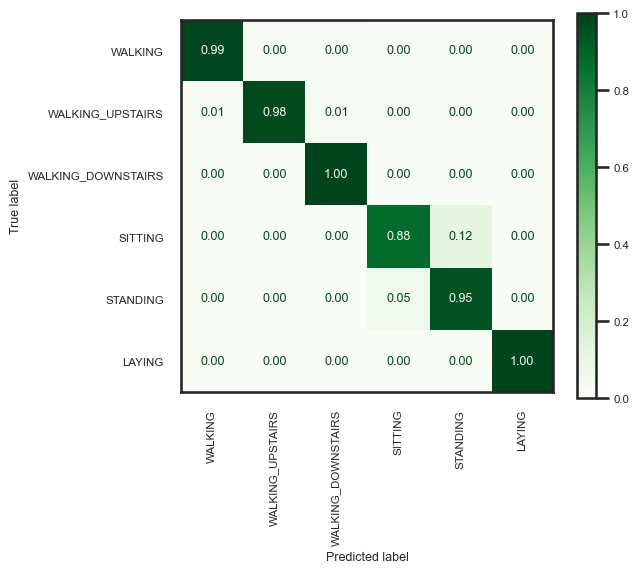

In [10]:
y_pred = np.argmax(prediction, axis=1)
plot_confusion_matrix(np.argmax(dataset['test']['label'], axis =1), y_pred, dataset['labels'])